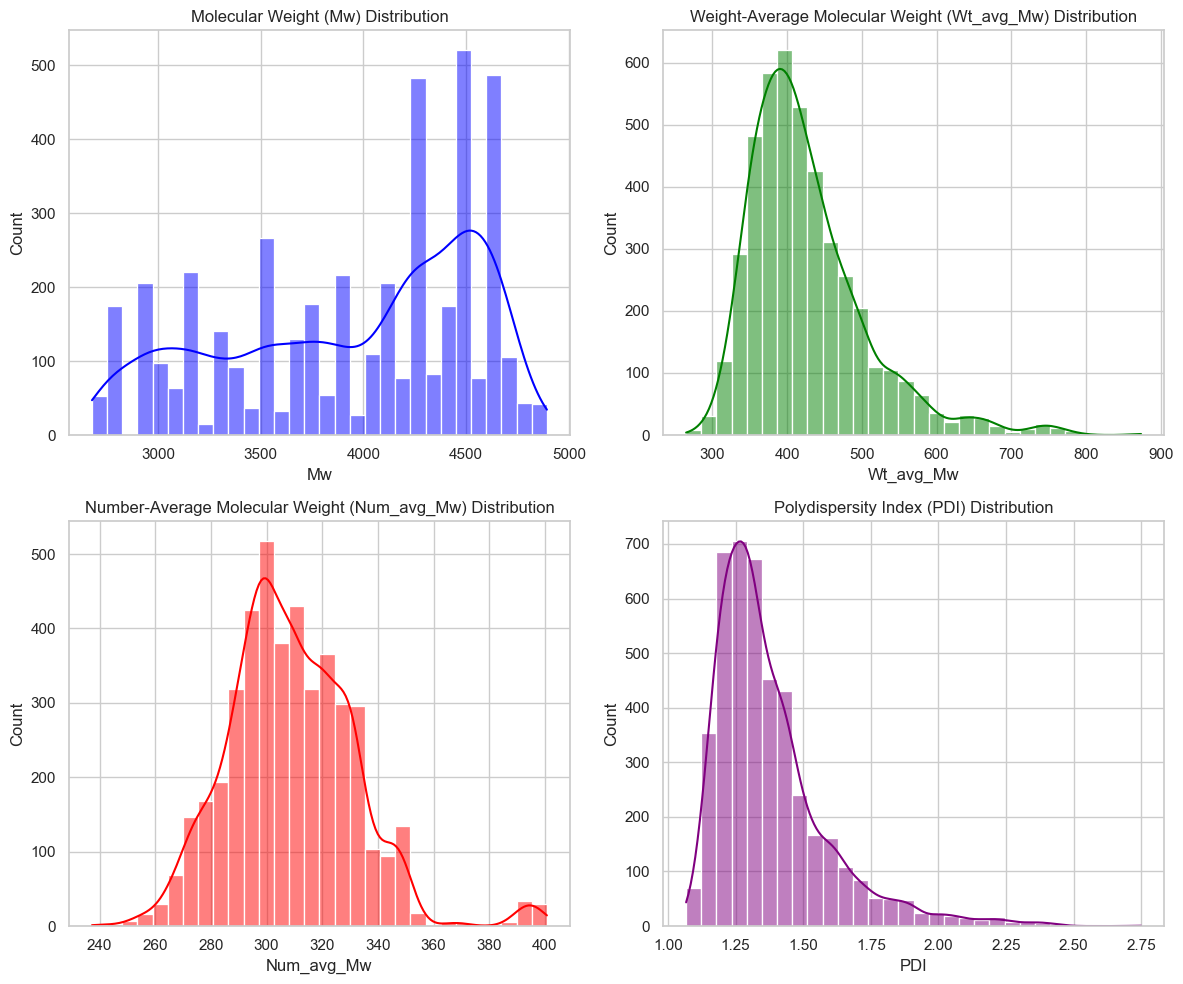

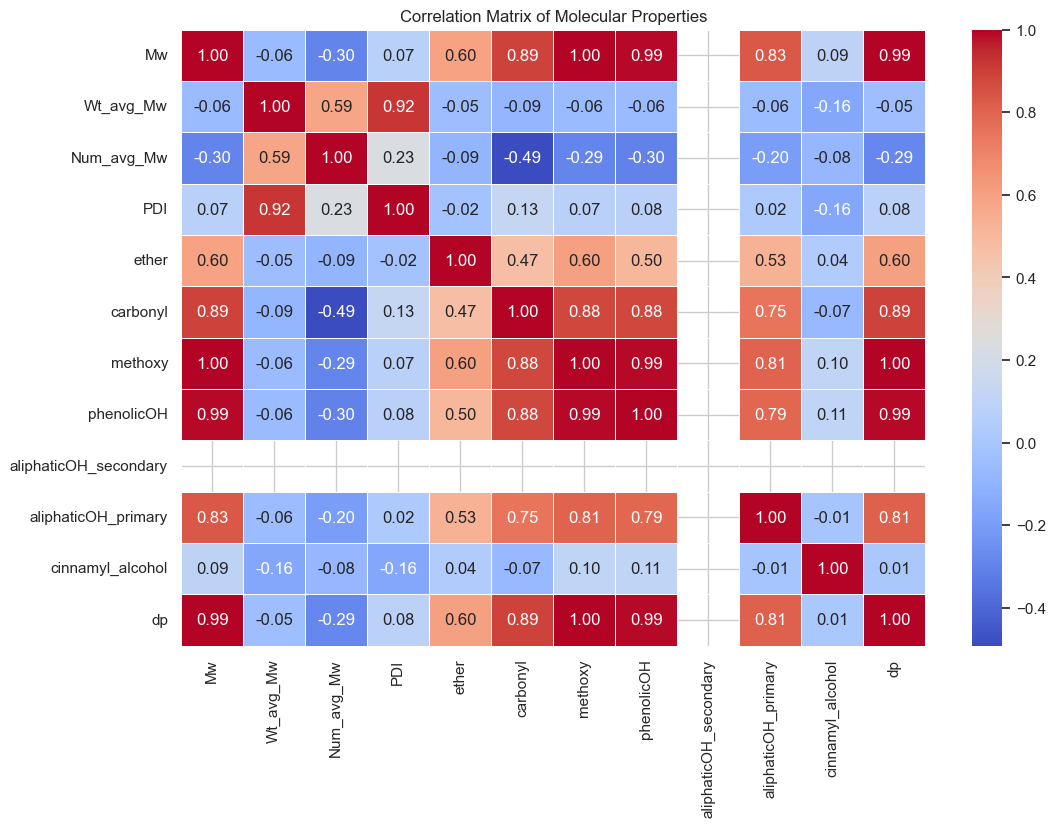

/var/folders/cz/42rd3gxs70n1cr_9pzry1mtr0000gp/T/ipykernel_59217/2296041724.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_melted, x="Functional Group", y="Count", palette="Set2")


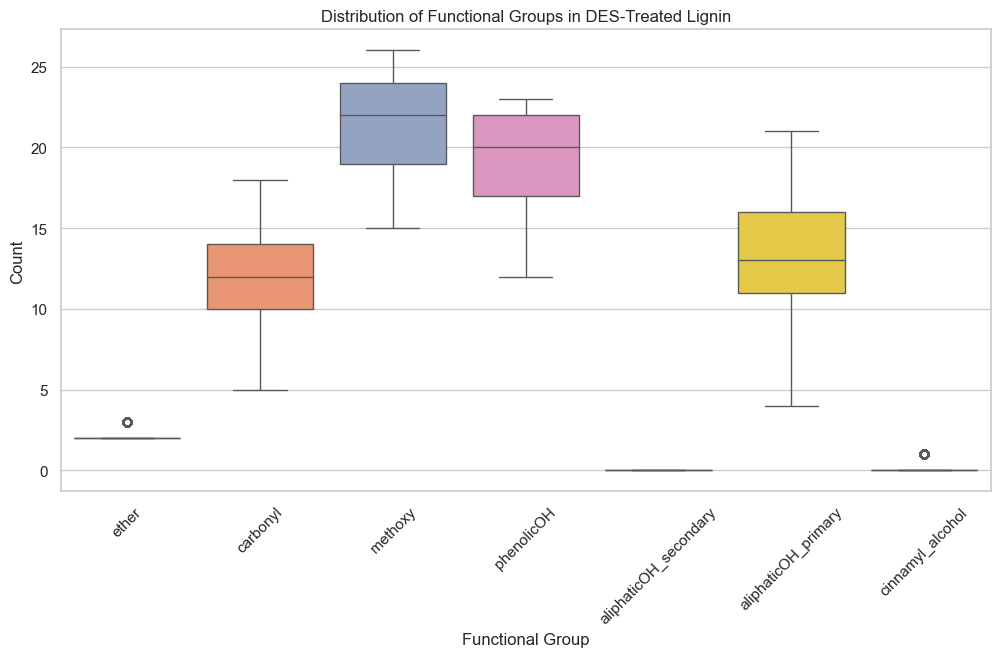

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = 'df_data_desl.csv'  # Replace with your actual file path
df = pd.read_csv(file_path)

# Remove unnamed columns
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# Set plot style
sns.set(style="whitegrid")

# 1. Distribution Plots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Histogram for Molecular Weight (Mw)
sns.histplot(df['Mw'], bins=30, kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Molecular Weight (Mw) Distribution')

# Histogram for Weight-Average Molecular Weight (Wt_avg_Mw)
sns.histplot(df['Wt_avg_Mw'], bins=30, kde=True, ax=axes[0, 1], color='green')
axes[0, 1].set_title(
    'Weight-Average Molecular Weight (Wt_avg_Mw) Distribution')

# Histogram for Number-Average Molecular Weight (Num_avg_Mw)
sns.histplot(df['Num_avg_Mw'], bins=30, kde=True, ax=axes[1, 0], color='red')
axes[1, 0].set_title(
    'Number-Average Molecular Weight (Num_avg_Mw) Distribution')

# Histogram for Polydispersity Index (PDI)
sns.histplot(df['PDI'], bins=30, kde=True, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Polydispersity Index (PDI) Distribution')

plt.tight_layout()
plt.savefig('distribution_plots.png', dpi=300)  # Save as high-resolution image
plt.show()

# 2. Correlation Heatmap
corr_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f",
            cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix of Molecular Properties")
# Save as high-resolution image
plt.savefig('correlation_heatmap.png', dpi=300)
plt.show()

# 3. Functional Group Analysis
functional_groups = ['ether', 'carbonyl', 'methoxy', 'phenolicOH',
                     'aliphaticOH_secondary', 'aliphaticOH_primary', 'cinnamyl_alcohol']

# Melt dataframe for easier plotting
df_melted = df.melt(id_vars=['Mw', 'PDI'], value_vars=functional_groups,
                    var_name="Functional Group", value_name="Count")

# Boxplot: Functional group count distribution
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_melted, x="Functional Group", y="Count", palette="Set2")
plt.xticks(rotation=45)
plt.title("Distribution of Functional Groups in DES-Treated Lignin")
plt.savefig('functional_group_distribution.png',
            dpi=300)  # Save as high-resolution image
plt.show()